## Blinded DR2 fits: with and without redshift-error correction

Use the **fit_env** kernel and run all cells. Each theory gets a corner plot comparing the **same blinded data** with `corr_dv` disabled and enabled. The defaults match `srun_data_fit.sh`: QSO1, P+B, holi-v3 covariance, and `corr_dv=pdf`.

Change `THEORIES`, `TRACER`, `STATS`, `CORR_DV`, or `params` below. Paths are reconstructed from the fit options, including the PDF content digest, rather than selected by wildcard. The availability table shows the expected directories. Only complete two-chain comparisons are plotted; rerun after missing fits finish. No mock-truth reference lines are drawn for these observed-data fits.

In [1]:
import sys
from pathlib import Path

main_dir = Path('/global/homes/s/shengyu/Y3/desi_y3_redshift_errors/main')
if str(main_dir) not in sys.path:
    sys.path.insert(0, str(main_dir))
from utils import setup_fit_env_notebook_paths
setup_fit_env_notebook_paths()

full_shape_dir = main_dir / 'full_shape'
if str(full_shape_dir) not in sys.path:
    sys.path.insert(0, str(full_shape_dir))

import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from getdist import plots

import run_fits
from helper import REDSHIFT_BIN_TRACER
from fit_tools import LikelihoodBuilder
from plotting_tools import PARAM_LABELS, read_chain

mpl.rcParams.update({
    'text.usetex': False,
    'mathtext.fontset': 'cm',
    'font.family': 'serif',
})

save_fig = False
OVERLEAF_DIR = main_dir.parent / 'overleaf' / 'figures'

In [2]:
# Select the comparisons. Each theory produces one figure with two chains.
THEORIES = ['folpsEFT', 'COMET']
TRACER = 'QSO1'
STATS = ['mesh2', 'mesh3']
CORR_DV = 'pdf'
PDF_FILE = '/pscratch/sd/s/shengyu/repeats/DA2/loa-v1/verr_mode/CDF_verr_nonparam_{tracer}_z{zmin}-{zmax}.npz'

FITS_ROOT = Path('/global/cfs/cdirs/desi/users/shengyu/Y3/full-shape/redshift_error_fits/blinded-data-dr2')
THEORY_CONFIG = {
    'folpsEFT': {'kmax': '0.20-0.20-0.20-0.03', 'fits_dir': FITS_ROOT / 'folpsEFT'},
    'COMET': {'kmax': '0.35-0.30-0.20-0.10', 'fits_dir': FITS_ROOT / 'COMET'},
}
version = 'blinded-data-dr2'
domain = 'obs'
cov_version = 'holi-v3'
REGION = 'GCcomb'
cosmo_params = 'base'
prior_basis = 'physical_aap'
COMET_MODEL = 'VDG_infty'
MESH3_THEORY_DK = 0.005
DAMPING = run_fits.DAMPING
DAMPING_METHOD = run_fits.DAMPING_METHOD

params = ['H0', 'Omega_m', 'logA']
# Optional nuisance parameters, if present in both chains:
# params += [f'{TRACER}.b2', f'{TRACER}.bs']

# Match the current plot_chain_bar.ipynb sample selection and smoothing.
remove_burnin = 0.6
step = 2
analysis_settings = {
    'smooth_scale_1D': 0.6,
    'smooth_scale_2D': 0.6,
    'fine_bins': 1024,
    'fine_bins_2D': 512,
}

stat_label = 'P+B' if 'mesh2' in STATS and 'mesh3' in STATS else ('P' if 'mesh2' in STATS else 'B')
CASES = [
    {'key': 'baseline', 'label': 'Without corr_dv', 'corr_dv': None, 'color': 'C0'},
    {'key': 'corrected', 'label': f'With corr_dv ({CORR_DV})', 'corr_dv': CORR_DV, 'color': '#279D8F'},
]

In [3]:
def resolve_chain_fn(expected):
    """Only inspect files within the fit directory selected by its options."""
    expected = Path(expected)
    candidates = [expected, expected.parent / 'samples' / 'samples_0.h5', expected.with_suffix('.h5')]
    return next((candidate for candidate in candidates if candidate.is_file()), None)


def expected_chain_fn(theory_model, case):
    config = THEORY_CONFIG[theory_model]
    catalog = {
        'version': version, 'domain': domain, 'tracer': TRACER,
        'zrange': REDSHIFT_BIN_TRACER[TRACER],
        'hod': 'base_dv' if TRACER.startswith('QSO') else 'base',
        'region': REGION, 'use_dv': 'None', 'z_evol': False,
    }
    # Observed data have no mock_id/mock_ids; covariance keeps its mock ensemble.
    correction = None
    if case['corr_dv'] is not None:
        correction = {'mode': case['corr_dv']}
        if case['corr_dv'].startswith('pdf'):
            correction['pdf_file'] = PDF_FILE
    observables = run_fits.build_observables(
        STATS, theory_model=theory_model, prior_basis=prior_basis, kmax=config['kmax'],
        damping=DAMPING, damping_method=DAMPING_METHOD,
        mesh3_theory_dk=MESH3_THEORY_DK, comet_model=COMET_MODEL,
        redshift_smearing=correction,
    )
    observables = run_fits.resolve_smearing_observables(observables, catalog)
    covariance = {
        'source': 'mock', 'version': cov_version, 'mock_ids': range(1000),
        'corrections': ['hartlap', 'percival'], 'rescale': False, 'domain': 'altmtl',
    }
    if REGION == 'GCcomb':
        covariance['region'] = 'ALL'
    builder = LikelihoodBuilder(
        observables=observables, catalog=catalog, covariance=covariance,
        cosmology={'model': cosmo_params, 'template': 'direct'},
        sampler=run_fits.build_sampler_args('pocomc', nchains=1, resume=False, stats=STATS),
        profiler={'maximize': {'niterations': run_fits.PROFILE_ITERATIONS}},
        cache_dir=config['fits_dir'] / '_cache',
    )
    return builder.get_fits_fn(fits_dir=config['fits_dir'], kind='chain', ichain=0)


# Show availability for every requested comparison, including missing fits.
chain_paths = {}
availability_rows = []
for theory_model in THEORIES:
    for case in CASES:
        expected = expected_chain_fn(theory_model, case)
        path = resolve_chain_fn(expected)
        chain_paths[theory_model, case['key']] = path
        availability_rows.append({
            'theory': theory_model, 'case': case['label'],
            'status': 'Available' if path is not None else 'Missing chain',
            'fit_directory': str(Path(expected).parent),
        })

availability_table = pd.DataFrame(availability_rows)
with pd.option_context('display.max_colwidth', None):
    display(availability_table)

ready_theories = [theory for theory in THEORIES
                  if all(chain_paths[theory, case['key']] is not None for case in CASES)]
for theory in ready_theories:
    paths = [chain_paths[theory, case['key']] for case in CASES]
    if len(set(paths)) != len(CASES):
        raise ValueError(f'{theory}: both cases resolve to the same chain.')
for theory in THEORIES:
    if theory not in ready_theories:
        print(f'{theory}: waiting for both chains; no comparison plotted.')

,theory,case,status,fit_directory
0,folpsEFT,Without corr_dv,Available,/global/cfs/cdirs/desi/users/shengyu/Y3/full-shape/redshift_error_fits/blinded-data-dr2/folpsEFT/cosmo-base_QSO1-z0.8-2.1-S2-S3-None_026e51f7
1,folpsEFT,With corr_dv (pdf),Available,/global/cfs/cdirs/desi/users/shengyu/Y3/full-shape/redshift_error_fits/blinded-data-dr2/folpsEFT/cosmo-base_QSO1-z0.8-2.1-S2-S3-None-rs-pdf_88efdf61
2,COMET,Without corr_dv,Available,/global/cfs/cdirs/desi/users/shengyu/Y3/full-shape/redshift_error_fits/blinded-data-dr2/COMET/cosmo-base_QSO1-z0.8-2.1-S2-S3-None_3bac135b
3,COMET,With corr_dv (pdf),Available,/global/cfs/cdirs/desi/users/shengyu/Y3/full-shape/redshift_error_fits/blinded-data-dr2/COMET/cosmo-base_QSO1-z0.8-2.1-S2-S3-None-rs-pdf_58ddd1de


In [4]:
def set_parameter_labels(samples):
    names = samples.getParamNames()
    nuisance_labels = {
        'b1': r'b_1', 'b1p': r'b_1', 'b2': r'b_2', 'b2p': r'b_2',
        'bs': r'b_s', 'bsp': r'b_s', 'alpha0': r'\alpha_0', 'alpha2': r'\alpha_2',
        'alpha0p': r'\alpha_0', 'alpha2p': r'\alpha_2',
        'sn0': r's_{n,0}', 'sn2': r's_{n,2}', 'sn0p': r's_{n,0}', 'sn2p': r's_{n,2}',
        'avir': r'a_{\rm vir}', 'X_FoG_pp': r'X_{\rm FoG}',
    }
    for param in names.names:
        param.label = nuisance_labels.get(
            param.name.rsplit('.', 1)[-1], PARAM_LABELS.get(param.name, param.label)
        ).strip('$')
    samples.setParamNames(names)

chains_by_theory = {}
for theory_model in THEORIES:
    chains_by_theory[theory_model] = {}
    for case in CASES:
        path = chain_paths[theory_model, case['key']]
        if path is None:
            continue
        chain = read_chain(path, remove_burnin=remove_burnin, step=step)
        missing = set(params) - set(map(str, chain.names()))
        if missing:
            raise ValueError(f'{path} is missing requested parameters: {sorted(missing)}')
        samples = chain.to_getdist(params=params, settings=analysis_settings)
        set_parameter_labels(samples)
        chains_by_theory[theory_model][case['key']] = samples

[000003.46]  09-21 13:13  jax._src.xla_bridge          ERROR    Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda12.initialize()
Traceback (most recent call last):
  File "/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/conda/lib/python3.12/site-packages/jax/_src/xla_bridge.py", line 497, in discover_pjrt_plugins
    plugin_module.initialize()
  File "/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/conda/lib/python3.12/site-packages/jax_plugins/xla_cuda12/__init__.py", line 348, in initialize
    _check_cuda_versions(raise_on_first_error=True)
  File "/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/conda/lib/python3.12/site-packages/jax_plugins/xla_cuda12/__init__.py", line 274, in _check_cuda_versions
    for d in range(cuda_versions.cuda_device_count())
                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: jaxlib/cuda/versions_helpers.c

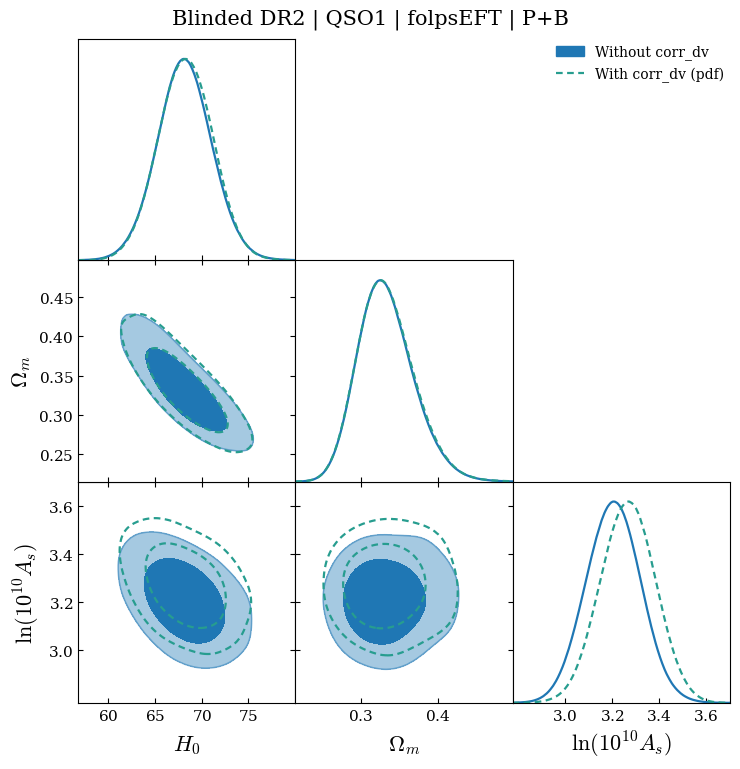

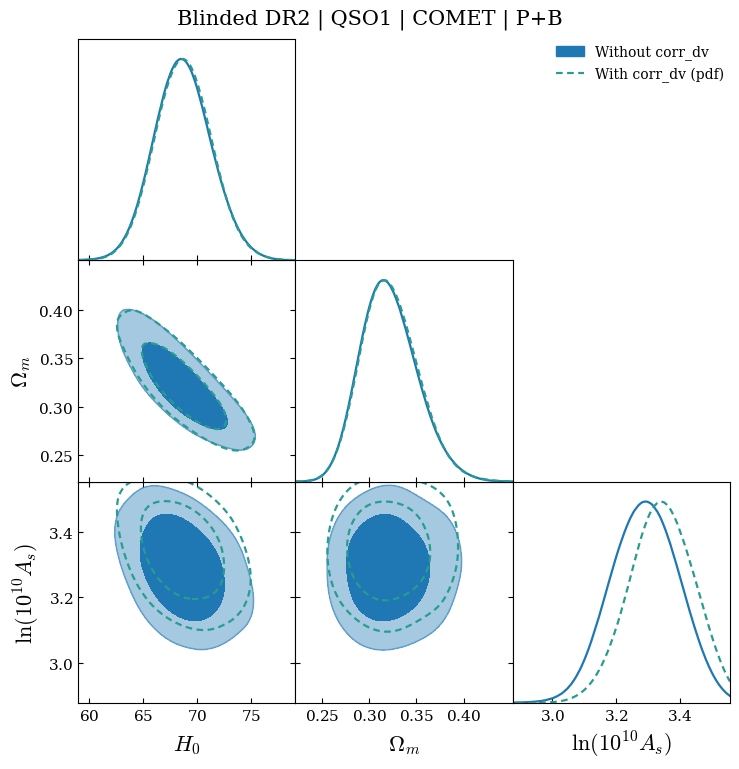

In [5]:
def plot_blinded_corner(samples, labels, theory_model):
    g = plots.get_subplot_plotter(width_inch=2.5 * len(params))
    g.settings.legend_fontsize = 12
    g.settings.axes_labelsize = 18
    g.settings.axes_fontsize = 13
    g.settings.figure_legend_frame = False
    g.settings.num_plot_contours = 2
    g.triangle_plot(
        samples, params, legend_labels=labels, legend_loc='upper right',
        contour_colors=[case['color'] for case in CASES],
        contour_lws=[1.6, 1.6], contour_ls=['-', '--'], filled=[True, False],
    )
    title = g.fig.suptitle(f'Blinded DR2 | {TRACER} | {theory_model} | {stat_label}',
                          y=1.02, fontsize=15)
    g.extra_artists.append(title)
    return g

corner_plots = {}
for theory_model in ready_theories:
    g = plot_blinded_corner(
        [chains_by_theory[theory_model][case['key']] for case in CASES],
        [case['label'] for case in CASES], theory_model,
    )
    corner_plots[theory_model] = g
    if save_fig:
        OVERLEAF_DIR.mkdir(parents=True, exist_ok=True)
        figure_fn = OVERLEAF_DIR / f'corner_blinded_dr2_{TRACER}_{REGION}_{theory_model}_{"-".join(STATS)}_corr-{CORR_DV}.pdf'
        g.export(str(figure_fn))
        print(f'Saved {figure_fn}')
    plt.show()
if not ready_theories:
    print('No complete with/without-correction pair is available yet. See the availability table above.')

## Parameter shifts after correction

As in `plot_corner.ipynb`, `tension_table` reports signed shifts $(\mu_{\rm with}-\mu_{\rm without})/\sigma_{\rm without}$ and $\mathrm{FoB}=\sqrt{\Delta\mu^T C_{\rm without}^{+}\Delta\mu}$ over `params`. These summarize the change between two fits to the same blinded data, using the uncorrected posterior covariance; they are not a comparison to a known true cosmology.

In [6]:
import numpy as np

def _getdist_weighted_mean_cov(chain, params):
    names = [name.name for name in chain.getParamNames().names]
    indices = [names.index(param) for param in params]
    samples = np.asarray(chain.samples)[:, indices]
    weights = np.asarray(chain.weights, dtype=float)
    weights = weights / weights.sum()
    mean = np.average(samples, axis=0, weights=weights)
    centered = samples - mean
    cov = (centered * weights[:, None]).T @ centered
    cov *= 1.0 / (1.0 - np.sum(weights**2))
    return mean, cov

def chain_tensions(chain_clean, chain_verr, params):
    mean_clean, cov_clean = _getdist_weighted_mean_cov(chain_clean, params)
    mean_verr, cov_verr = _getdist_weighted_mean_cov(chain_verr, params)
    delta = mean_verr - mean_clean
    cov_delta = cov_clean
    # param_tensions = np.abs(delta) / np.sqrt(np.diag(cov_delta))
    param_tensions = delta / np.sqrt(np.diag(cov_clean))
    # FoB relative to the baseline fit uses only the baseline covariance.
    fob = np.sqrt(delta @ np.linalg.pinv(cov_delta) @ delta)
    return dict(zip(params, param_tensions)) | {'FoB': float(fob)}

tension_rows = []
for theory_model in ready_theories:
    row = {'theory': theory_model, 'tracer': TRACER, 'stats': stat_label,
           'comparison': f'{CORR_DV} minus no correction'}
    row.update(chain_tensions(
        chains_by_theory[theory_model]['baseline'],
        chains_by_theory[theory_model]['corrected'], params,
    ))
    tension_rows.append(row)

tension_table = pd.DataFrame(tension_rows, columns=['theory', 'tracer', 'stats', 'comparison'] + params + ['FoB'])
tension_table = tension_table.set_index(['theory', 'tracer', 'stats', 'comparison'])
if not tension_table.empty:
    display(tension_table.style.format({col: '{:.2f}' for col in params + ['FoB']}))
else:
    print('Parameter shifts will be shown once both chains are available.')

,,,,H0,Omega_m,logA,FoB
theory,tracer,stats,comparison,,,,
folpsEFT,QSO1,P+B,pdf minus no correction,0.04,0.01,0.54,0.76
COMET,QSO1,P+B,pdf minus no correction,0.02,0.02,0.49,0.64
